# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [ ]:
# Preliminares
import pandas as pd

from src.modeling import (
    cargar_datos_clean, preprocesar_forex, separar_datos_live,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots 
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 965 entries, 2007-04-30 to 2026-10-26
Data columns (total 95 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   AUDUSD_Close_return                           965 non-null    float64
 1   EURUSD_Close_return                           965 non-null    float64
 2   GBPUSD_Close_return                           965 non-null    float64
 3   USDCAD_Close_return                           965 non-null    float64
 4   USDCHF_Close_return                           965 non-null    float64
 5   USDJPY_Close_return                           965 non-null    float64
 6   EURUSD_Close_return_lag1                      965 non-null    float64
 7   GBPUSD_Close_return_lag1                      965 non-null    float64
 8   USDJPY_Close_return_lag1                      965 non-null    float64
 9   USDCHF_Close_return_lag1                      

## Analisis de variables

In [2]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

In [3]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "Volume_pct_diff_sma20"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
Oil_Volume_pct_diff_sma20_lag1_yeo,965.0,-0.002184,0.998731,-3.458363,-0.621113,0.051813,0.629412,5.473446
Gold_Volume_pct_diff_sma20_lag1_yeo,965.0,0.000745,1.000768,-0.953149,-0.881076,-0.673939,0.900778,2.177346
SPY_Volume_pct_diff_sma20_lag1_yeo,965.0,0.000482,1.000924,-3.444621,-0.636162,-0.010918,0.663332,3.110249


In [4]:
# Asimetrias general
mostrar_asimetrias(df_clean)

USDCAD_Close_return                             3.254536
Oil_Close_max20_pct_diff_Close_lag1_log1p       2.821499
VIX_level                                       2.368104
SPY_Close_max20_pct_diff_Close_lag1_log1p       2.217511
USDCAD_Close_var20_lag1_log                     2.010950
USDCAD_Close_max20_pct_diff_Close_lag1_log1p    1.872004
EURUSD_Close_max20_pct_diff_Close_lag1_log1p    1.435832
Gold_Close_max20_pct_diff_Close_lag1_log1p      1.402734
GBPUSD_High_Low_spread_lag1_log                 1.385475
GBPUSD_Close_max20_pct_diff_Close_lag1_log1p    1.342192
USDCHF_Close_max20_pct_diff_Close_lag1_log1p    1.308341
USDJPY_High_Low_spread_lag1_log                 1.245412
USDJPY_Close_max20_pct_diff_Close_lag1_log1p    1.157409
AUDUSD_Close_max20_pct_diff_Close_lag1_log1p    1.122838
USDCHF_Close_var20_lag1_log                     1.080074
EURUSD_High_Low_spread_lag1_log                 0.869145
Oil_Close_var20_lag1_log                        0.786868
STLFSI_delta_20d_yeo           

In [5]:
# Asimetria por grupo
cadena = "Open_pct_diff_last_Close"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

USDJPY_Open_pct_diff_last_Close_yeo    0.749210
SPY_Open_pct_diff_last_Close_yeo       0.479051
Oil_Open_pct_diff_last_Close_yeo       0.373909
EURUSD_Open_pct_diff_last_Close_yeo    0.086990
USDCHF_Open_pct_diff_last_Close_yeo   -0.036410
Gold_Open_pct_diff_last_Close_yeo     -0.044801
GBPUSD_Open_pct_diff_last_Close_yeo   -0.310723
USDCAD_Open_pct_diff_last_Close_yeo   -0.621093
AUDUSD_Open_pct_diff_last_Close_yeo   -0.847507


Cont


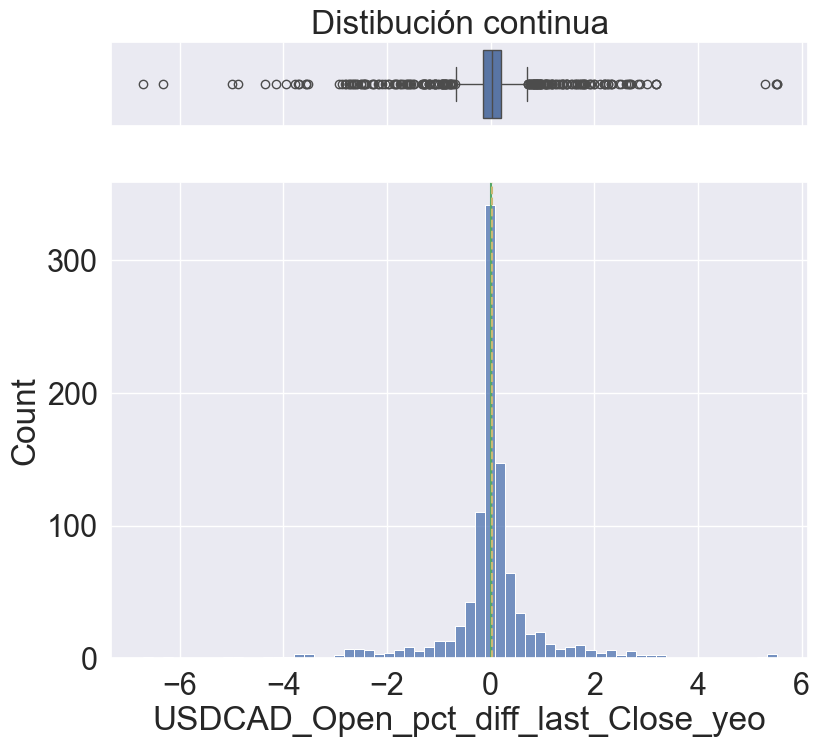

In [6]:
# Visualizar columna
col = 'USDCAD_Open_pct_diff_last_Close_yeo'
pintar_columna(df_clean[col])

In [7]:
# Tabla de Correlaciones
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
363,USDCAD_Close_sma20_pct_diff_sma50_lag1,AUDUSD_Close_sma20_pct_diff_sma50_lag1,0.833983
1685,SPY_Close_max20_pct_diff_Close_lag1_log1p,VIX_level,0.787558
423,USDCHF_Close_sma20_pct_diff_sma50_lag1,EURUSD_Close_sma20_pct_diff_sma50_lag1,0.785406
1960,GBPUSD_High_pct_diff_Close_lag1_yeo,GBPUSD_Close_return_lag1,0.768456
1786,USDCHF_Close_max20_pct_diff_Close_lag1_log1p,EURUSD_Close_min20_pct_diff_Close_lag1,0.758307
2024,USDJPY_High_pct_diff_Close_lag1_yeo,USDJPY_Close_return_lag1,0.751271
1321,USDCHF_Close_var20_lag1_log,EURUSD_Close_var20_lag1_log,0.749800
2837,USDCHF_Low_pct_diff_Close_lag1_yeo,EURUSD_High_pct_diff_Close_lag1_yeo,0.749648
2551,EURUSD_Low_pct_diff_Close_lag1_yeo,USDCHF_High_pct_diff_Close_lag1_yeo,0.743009
935,SPY_High_Low_spread_lag1_log,VIX_level,0.722843


## Analisis de labels

In [8]:
simbolo_objetivo = 'EURUSD'
# Cargar fichero de precios
df = cargar_datos_clean()
df = preprocesar_forex(df,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df.index.max()
df_train, df_live = separar_datos_live(df=df, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles
objetivo = f"{simbolo_objetivo}_Close_return"
objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )


print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker EURUSD ---
   categoria  lim_inferior  lim_superior
0          1     -0.042661     -0.004680
1          2     -0.004680      0.004647
2          3      0.004647      0.044001


In [9]:
df_train[objetivo_cat].value_counts()

EURUSD_Close_return_cat
3    322
1    321
2    321
Name: count, dtype: int64

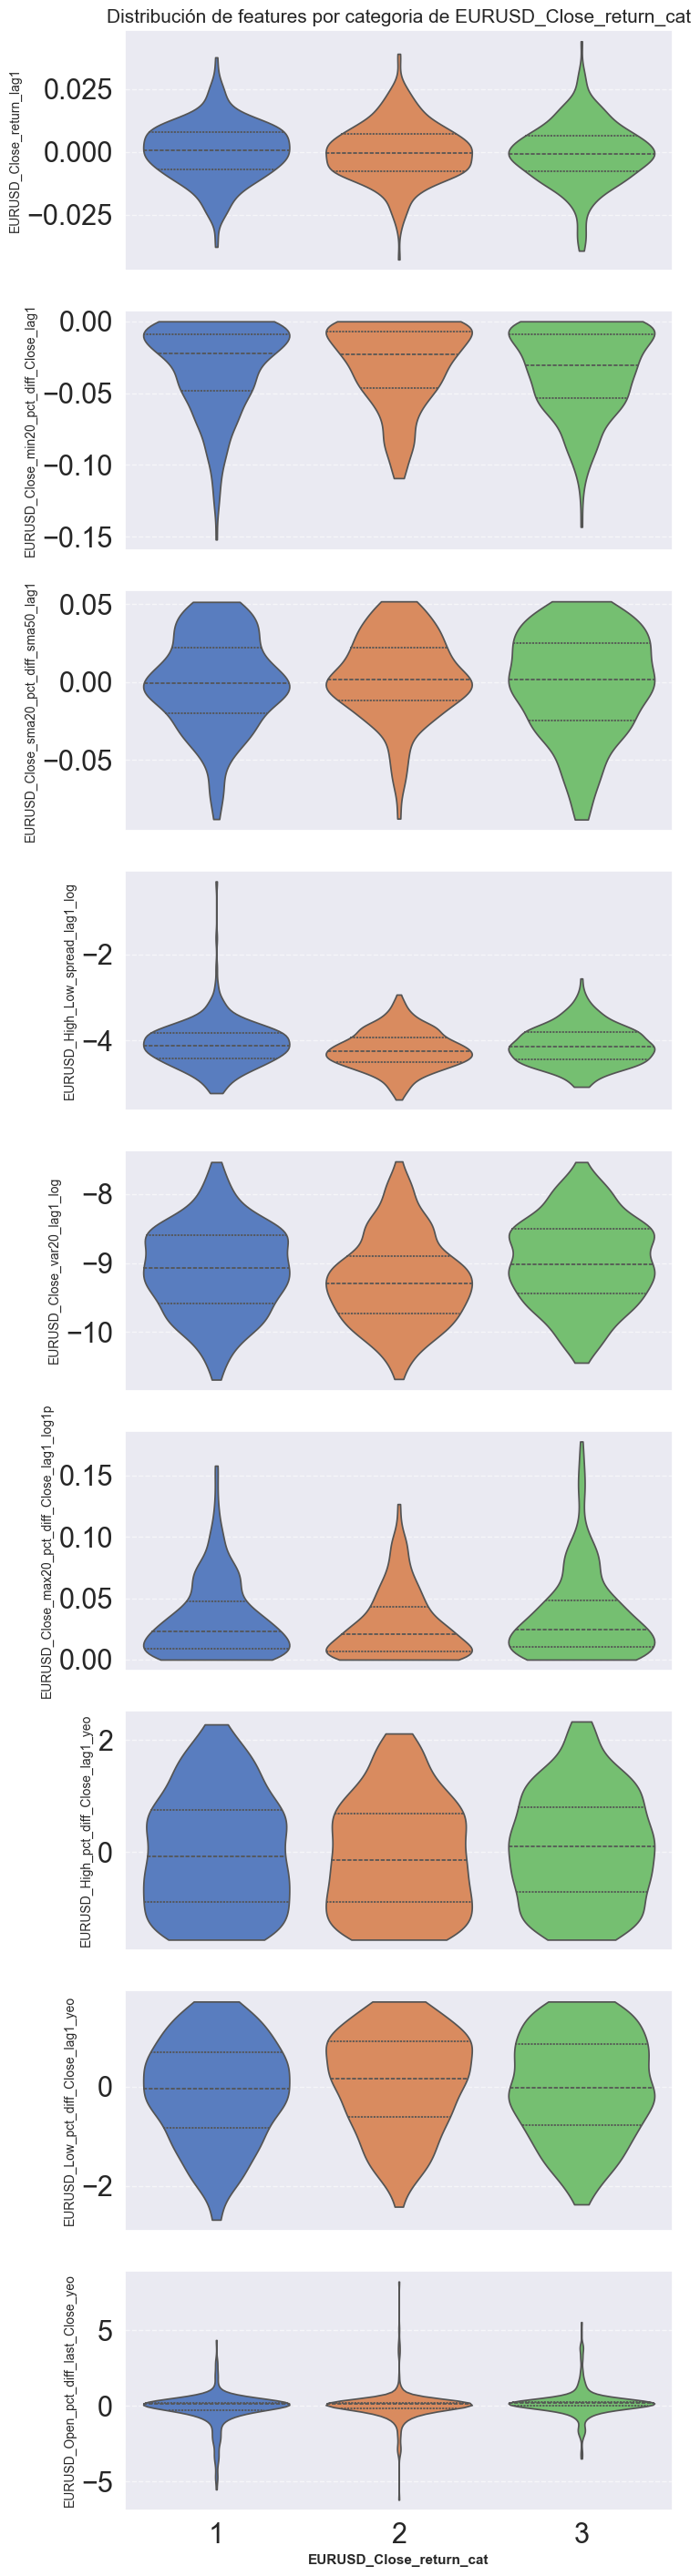

In [10]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]

# Filtrar por grupo de variables
cadena = "EURUSD"
columnas = encontrar_columnas(columnas_target=numeric_cols, cadena=cadena)

pintar_violin_plots(
    df=df_train,
    numeric_cols=columnas,
    target_col=target_col
)